In [1]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/

cp: cannot stat 'kaggle.json': No such file or directory


In [2]:
!kaggle datasets download vipoooool/new-plant-diseases-dataset

Dataset URL: https://www.kaggle.com/datasets/vipoooool/new-plant-diseases-dataset
License(s): copyright-authors
100% 2.70G/2.70G [00:31<00:00, 91.0MB/s]



In [3]:
import zipfile
zip_ref = zipfile.ZipFile('/content/new-plant-diseases-dataset.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

In [4]:
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
train_dir="/content/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train"
training_data=keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False,
    pad_to_aspect_ratio=False,
    data_format=None,
    format="tf",
    verbose=True,
)


Found 70295 files belonging to 38 classes.


In [6]:
validation_dir="/content/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid"
validation_data=keras.utils.image_dataset_from_directory(
    validation_dir,
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False,
    pad_to_aspect_ratio=False,
    data_format=None,
    format="tf",
    verbose=True,
)


Found 17572 files belonging to 38 classes.


In [7]:
training_data


<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 38), dtype=tf.float32, name=None))>

In [16]:
from keras.layers import Dense,Conv2D,MaxPooling2D,Flatten,Dropout
from keras.models import Sequential

In [17]:
model=Sequential()

model.add(Conv2D(32,(3,3),padding="same",activation='relu',input_shape=(128,128,3)))
model.add(MaxPooling2D(2,2))
model.add(Conv2D(64,(3,3),activation='relu',padding='same'))
model.add(MaxPooling2D(2,2))
model.add(Conv2D(128,(3,3),activation='relu',padding='same'))
model.add(MaxPooling2D(2,2))
model.add(Conv2D(256,(3,3),activation='relu',padding='same'))
model.add(MaxPooling2D(2,2))
model.add(Dropout(0.25))
model.add(Flatten())
model.add(Dense(1024,activation='relu'))
model.add(Dropout(0.4))
model.add(Dense(38,activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [18]:
optimizer=keras.optimizers.Adam(learning_rate=0.001)
model.compile(optimizer=optimizer,loss='categorical_crossentropy',metrics=['accuracy'])

In [19]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │    16,778,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 38)             │        38,950 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,205,606 (65.63 MB)

 Trainable params: 17,205,606 (65.63 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
from tensorflow.keras.callbacks import EarlyStopping
early_stop=EarlyStopping(monitor='val_loss',patience=2,restore_best_weights=True)

In [24]:
training_history=model.fit(x=training_data,validation_data=validation_data,epochs=10,callbacks=[early_stop])

Epoch 1/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 79s 36ms/step - accuracy: 0.9226 - loss: 0.2760 - val_accuracy: 0.9188 - val_loss: 0.3007
Epoch 2/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 68s 31ms/step - accuracy: 0.9231 - loss: 0.2824 - val_accuracy: 0.9253 - val_loss: 0.2698
Epoch 3/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 67s 30ms/step - accuracy: 0.9274 - loss: 0.2629 - val_accuracy: 0.9449 - val_loss: 0.2117
Epoch 4/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 67s 30ms/step - accuracy: 0.9275 - loss: 0.2700 - val_accuracy: 0.9334 - val_loss: 0.2478
Epoch 5/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 83s 31ms/step - accuracy: 0.9227 - loss: 0.2863 - val_accuracy: 0.9337 - val_loss: 0.2722


In [25]:
train_loss,train_acc=model.evaluate(training_data)

2197/2197 ━━━━━━━━━━━━━━━━━━━━ 47s 22ms/step - accuracy: 0.9858 - loss: 0.0456


In [28]:
val_loss,val_acc=model.evaluate(validation_data)

550/550 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.9449 - loss: 0.2117


In [29]:
model.save("trained_model.h5")

In [31]:
model.save("trained_model.keras")


In [30]:
import json
with open("training_hist.json","w") as f:
  json.dump(training_history.history,f)

In [50]:
class_name=validation_data.class_names
class_name

['Apple___Apple_scab',
 'Apple___Black_rot',
 'Apple___Cedar_apple_rust',
 'Apple___healthy',
 'Blueberry___healthy',
 'Cherry_(including_sour)___Powdery_mildew',
 'Cherry_(including_sour)___healthy',
 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
 'Corn_(maize)___Common_rust_',
 'Corn_(maize)___Northern_Leaf_Blight',
 'Corn_(maize)___healthy',
 'Grape___Black_rot',
 'Grape___Esca_(Black_Measles)',
 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
 'Grape___healthy',
 'Orange___Haunglongbing_(Citrus_greening)',
 'Peach___Bacterial_spot',
 'Peach___healthy',
 'Pepper,_bell___Bacterial_spot',
 'Pepper,_bell___healthy',
 'Potato___Early_blight',
 'Potato___Late_blight',
 'Potato___healthy',
 'Raspberry___healthy',
 'Soybean___healthy',
 'Squash___Powdery_mildew',
 'Strawberry___Leaf_scorch',
 'Strawberry___healthy',
 'Tomato___Bacterial_spot',
 'Tomato___Early_blight',
 'Tomato___Late_blight',
 'Tomato___Leaf_Mold',
 'Tomato___Septoria_leaf_spot',
 'Tomato___Spider_mites Two-spotted_

In [32]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [34]:
model=keras.models.load_model("trained_model.keras")

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 14 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]], shape=(256, 256, 3), dtype=uint8)
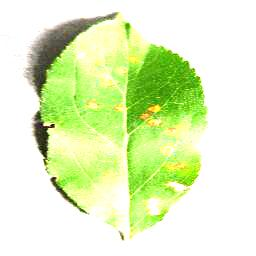

In [67]:
import cv2
img_path="/content/test/test/AppleCedarRust1.JPG"
img=cv2.imread(img_path)
img=cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
img

In [64]:
image=tf.keras.preprocessing.image.load_img(img_path,target_size=(128,128))
input_arr=tf.keras.preprocessing.image.img_to_array(image)
input_arr=np.array([input_arr])
input_arr.shape

(1, 128, 128, 3)

In [48]:
prediction=model.predict(input_arr)
prediction.shape,prediction

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


((1, 38),
 array([[7.5365192e-10, 1.6271541e-09, 9.6620953e-01, 1.9282340e-11,
         2.4098563e-05, 4.7383035e-11, 4.7422522e-12, 2.1372355e-12,
         7.3392986e-16, 3.7600742e-17, 1.1137002e-16, 4.8593442e-08,
         2.6907213e-10, 5.6677651e-10, 1.1624004e-12, 7.8964267e-14,
         3.8676280e-12, 1.2229152e-09, 1.3525070e-07, 2.8320972e-07,
         8.0160249e-13, 1.0149458e-11, 4.6939690e-06, 4.7675062e-06,
         1.4929191e-12, 3.7697130e-16, 1.7557107e-07, 5.7312242e-08,
         5.7732664e-12, 1.9462509e-07, 9.5585273e-09, 4.5404194e-11,
         6.0386360e-06, 3.2827285e-07, 3.3735972e-02, 1.8011838e-10,
         1.3300979e-05, 2.4943427e-07]], dtype=float32))

In [49]:
result_idx=np.argmax(prediction)
result_idx

np.int64(2)

In [51]:
class_name=['Apple___Apple_scab',
 'Apple___Black_rot',
 'Apple___Cedar_apple_rust',
 'Apple___healthy',
 'Blueberry___healthy',
 'Cherry_(including_sour)___Powdery_mildew',
 'Cherry_(including_sour)___healthy',
 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
 'Corn_(maize)___Common_rust_',
 'Corn_(maize)___Northern_Leaf_Blight',
 'Corn_(maize)___healthy',
 'Grape___Black_rot',
 'Grape___Esca_(Black_Measles)',
 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
 'Grape___healthy',
 'Orange___Haunglongbing_(Citrus_greening)',
 'Peach___Bacterial_spot',
 'Peach___healthy',
 'Pepper,_bell___Bacterial_spot',
 'Pepper,_bell___healthy',
 'Potato___Early_blight',
 'Potato___Late_blight',
 'Potato___healthy',
 'Raspberry___healthy',
 'Soybean___healthy',
 'Squash___Powdery_mildew',
 'Strawberry___Leaf_scorch',
 'Strawberry___healthy',
 'Tomato___Bacterial_spot',
 'Tomato___Early_blight',
 'Tomato___Late_blight',
 'Tomato___Leaf_Mold',
 'Tomato___Septoria_leaf_spot',
 'Tomato___Spider_mites Two-spotted_spider_mite',
 'Tomato___Target_Spot',
 'Tomato___Tomato_Yellow_Leaf_Curl_Virus',
 'Tomato___Tomato_mosaic_virus',
 'Tomato___healthy']

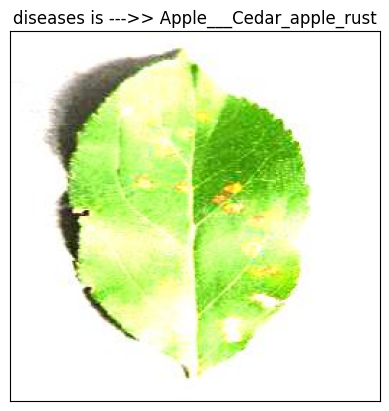

In [56]:
model_prediction=class_name[result_idx]
model_prediction
plt.imshow(img)
plt.xticks([])
plt.yticks([])
plt.title(f'diseases name  {model_prediction}')
plt.show()

In [ ]:
# Export the trained model and its exact class order for the FastAPI app.
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile
import json

artifact_dir = Path("plant_disease_api_artifacts")
artifact_dir.mkdir(exist_ok=True)
model_path = artifact_dir / "trained_model.keras"
classes_path = artifact_dir / "class_names.json"

model.save(model_path)
class_names_for_api = list(training_data.class_names)
assert len(class_names_for_api) == int(model.output_shape[-1])
classes_path.write_text(json.dumps(class_names_for_api, indent=2), encoding="utf-8")

bundle_path = Path("plant_model_bundle.zip")
with ZipFile(bundle_path, "w", compression=ZIP_DEFLATED) as bundle:
    bundle.write(model_path, arcname="trained_model.keras")
    bundle.write(classes_path, arcname="class_names.json")

from google.colab import files
files.download(str(bundle_path))
